Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


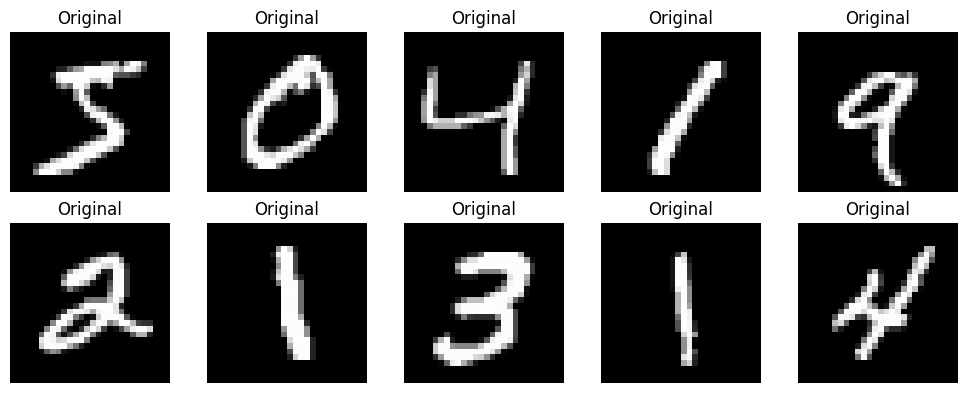

Training data after flattening: (60000, 784)
Testing data after flattening: (10000, 784)


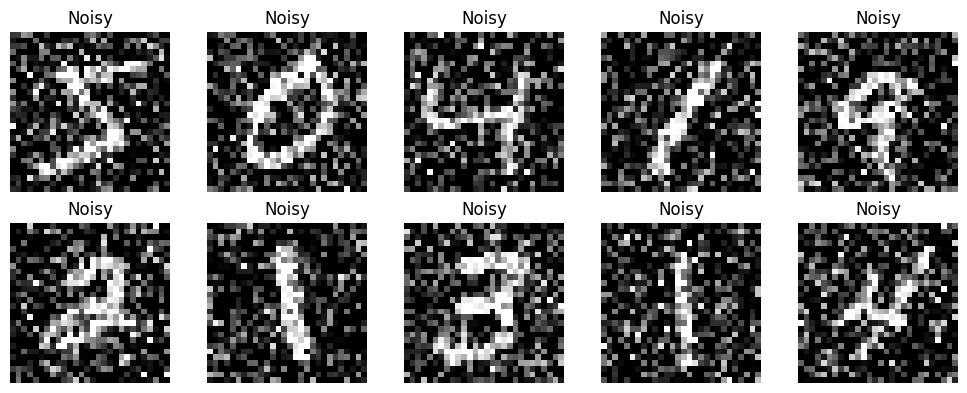

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - loss: 0.2101 - val_loss: 0.1556
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.1458 - val_loss: 0.1361
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.1337 - val_loss: 0.1284
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.1275 - val_loss: 0.1238
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.1237 - val_loss: 0.1210
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.1215 - val_loss: 0.1191
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.1201 - val_loss: 0.1191
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.1189 - val_loss: 0.1174
Epoch 9/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.1179 - val_loss: 0.1166
Epoch 10/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.1171 - val_loss: 0.1162
Epoch 11/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.1164 - val_loss: 0.1153
Epoch 12/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 

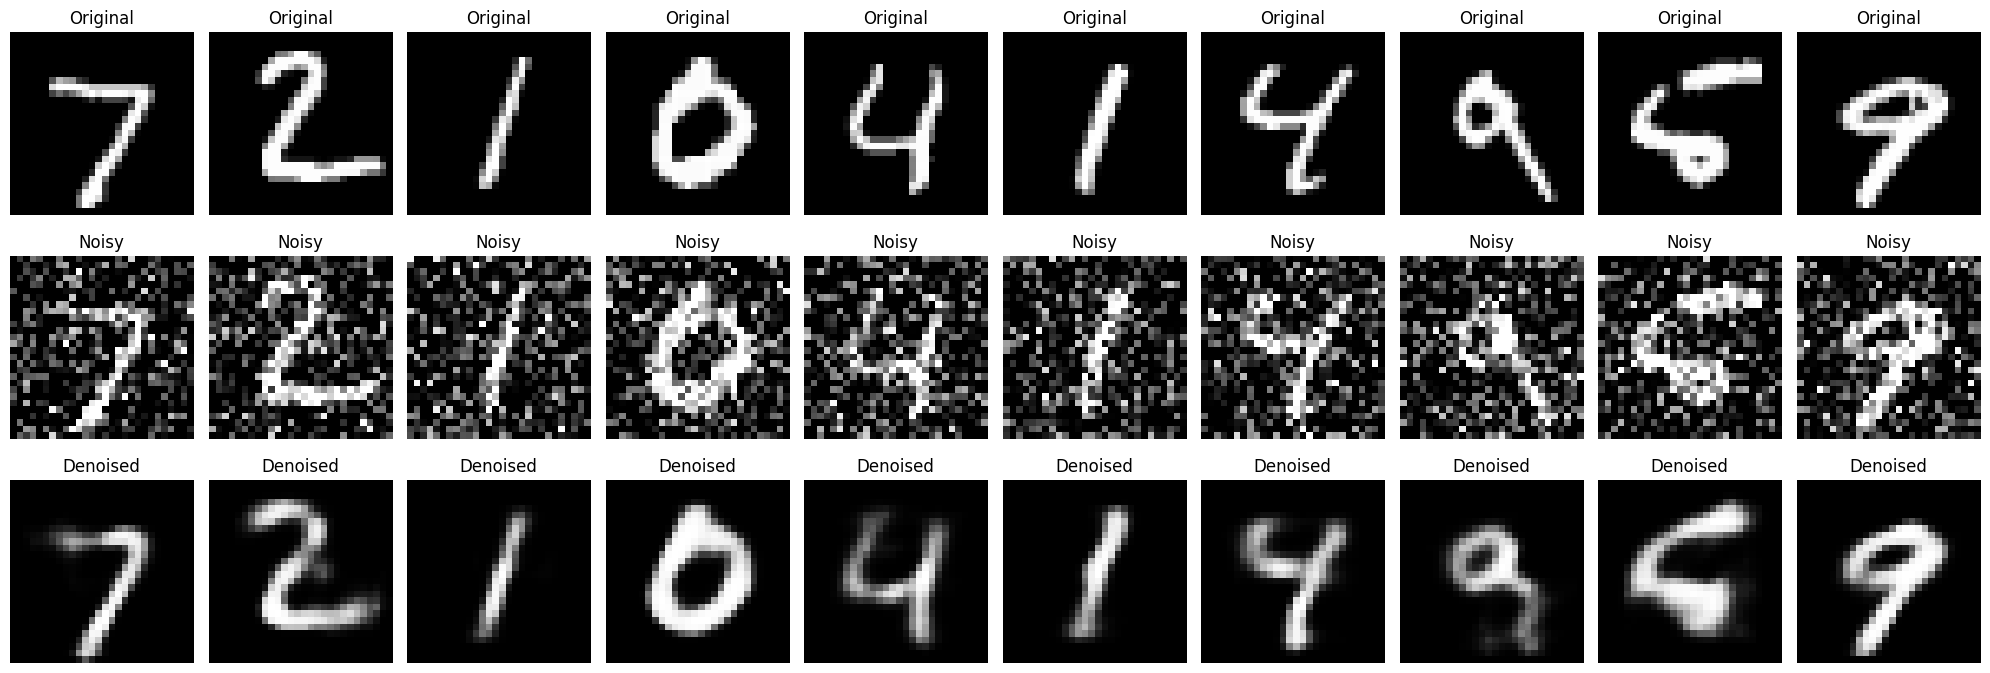

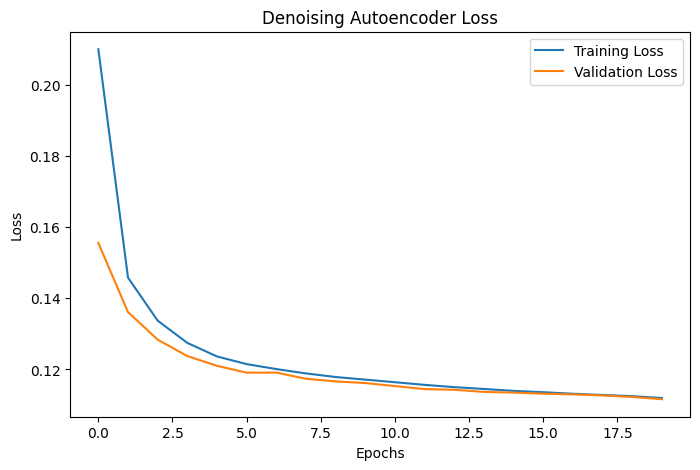

In [2]:

# STEP 1: Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# STEP 2: Load MNIST dataset

(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# STEP 3: Display original images

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

plt.tight_layout()
plt.show()

# STEP 4: Normalize images

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# STEP 5: Flatten images

x_train = x_train.reshape((len(x_train), 784))
x_test = x_test.reshape((len(x_test), 784))

print("Training data after flattening:", x_train.shape)
print("Testing data after flattening:", x_test.shape)

# STEP 6: Add Gaussian noise to images

noise_factor = 0.4

x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_test.shape
)

# Keep pixel values between 0 and 1

x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)

# STEP 7: Display noisy images

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_noisy[i].reshape(28, 28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

plt.tight_layout()
plt.show()

# STEP 8: Define the denoising autoencoder

autoencoder = keras.Sequential([
    keras.Input(shape=(784,)),

    # Encoder
    layers.Dense(128, activation="relu"),
    layers.Dense(32, activation="relu"),

    # Decoder
    layers.Dense(128, activation="relu"),
    layers.Dense(784, activation="sigmoid")
])

# STEP 9: Compile the model

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

# STEP 10: Display model summary

autoencoder.summary()

# STEP 11: Train the denoising autoencoder

history = autoencoder.fit(
    x_train_noisy,
    x_train,
    epochs=20,
    batch_size=128,
    shuffle=True,
    validation_data=(x_test_noisy, x_test),
    verbose=1
)

# STEP 12: Reconstruct clean images

denoised_images = autoencoder.predict(x_test_noisy)

print("Noisy test data shape:", x_test_noisy.shape)
print("Denoised image shape:", denoised_images.shape)

# STEP 13: Display original, noisy and denoised images

n = 10

plt.figure(figsize=(20, 7))

for i in range(n):

    # Original images
    plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Noisy images
    plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    # Denoised images
    plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(denoised_images[i].reshape(28, 28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()

# STEP 14: Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Denoising Autoencoder Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
